# 11 — Análise económica como dimensão **secundária** da decisão clínica

## ⚕️ Princípio orientador (não-financeiro)

**A justificação primária para minimizar Falsos Negativos é ética, não económica.** Em saúde, FN clínico (doente classificado como saudável) é eticamente inaceitável sob o princípio da **não-maleficência** (*primum non nocere*). Cada FN representa:

- **Dano por omissão**: paciente vai para casa doente; doença progride.
- **Perda funcional irreversível** em DPOC (tecido pulmonar não regenera).
- **Negação do direito do paciente** a saber o seu diagnóstico (princípio da autonomia).
- **Perpetuação do subdiagnóstico** (86% em Portugal — ONDR) que o sistema deveria combater.

Por outro lado, FP é **remediável** (médico corrige na consulta).

## A análise económica é consequência mensurável

Quantificamos abaixo o impacto financeiro como **forma de comunicar a gestão hospitalar** a relevância de minimizar FN — não como argumento primário. Os custos abaixo são **proxies imperfeitos do dano clínico real**:

- **FN em COPD/URTI**: ~€1.500–4.000 (internação tardia) — mas o custo verdadeiro é qualidade de vida + sobrevida perdida, não dinheiro.
- **FP**: ~€40–80 (consulta extra) — facilmente remediável.

Por argmax simples (threshold = 0.5 para cada classe) maximizamos **accuracy**, não **valor clínico**.
Aqui vamos:

1. Calcular curvas **ROC e Precision-Recall** por classe (one-vs-rest).
2. Ajustar threshold de cada classe para atingir **recall mínimo (95% para Disease, 80% para URTI)**.
3. Modelar **custo total** (FN × custo_FN + FP × custo_FP) em função do threshold.
4. Encontrar o threshold de menor custo esperado.
5. Traduzir em **economia anual** baseada em volume típico de auscultaões em um hospital.

In [1]:
import sys, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (roc_curve, auc, precision_recall_curve,
                              confusion_matrix, classification_report)

from src import config
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

## 1. Reproduzir as probabilidades OOF do pipeline final

In [2]:
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename','patient_id','equipment','chest_location','label_multi','label_binary')]
X = feats_df[FEATURE_COLS].values
le = LabelEncoder(); y = le.fit_transform(feats_df['label_multi'])
groups = feats_df['patient_id'].values
equipment = feats_df['equipment'].values
CLASSES = list(le.classes_)
EQUIPMENT_CATS = sorted(set(equipment))

# Pipeline com residualização + LogReg + calibração isotónica em OOF
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
proba_uncal = np.zeros((len(y), len(CLASSES)))
for tr, te in cv.split(X, y, groups):
    ohe = OneHotEncoder(sparse_output=False, categories=[EQUIPMENT_CATS])
    E_tr = ohe.fit_transform(equipment[tr].reshape(-1,1))
    E_te = ohe.transform(equipment[te].reshape(-1,1))
    lr = LinearRegression().fit(E_tr, X[tr])
    Xr_tr = X[tr] - lr.predict(E_tr); Xr_te = X[te] - lr.predict(E_te)
    sc = StandardScaler().fit(Xr_tr)
    Xs_tr = sc.transform(Xr_tr); Xs_te = sc.transform(Xr_te)
    clf = LogisticRegression(max_iter=3000, class_weight='balanced').fit(Xs_tr, y[tr])
    proba_uncal[te] = clf.predict_proba(Xs_te)

# Calibração isotónica
proba_cal = np.zeros_like(proba_uncal)
for k, cls in enumerate(CLASSES):
    ir = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(
        proba_uncal[:, k], (y == k).astype(float))
    proba_cal[:, k] = ir.predict(proba_uncal[:, k])
s = proba_cal.sum(axis=1, keepdims=True); s[s==0]=1; proba_cal/=s
print(f'Probas calibradas OOF prontas: {proba_cal.shape}')

Probas calibradas OOF prontas: (851, 3)


## 2. Curvas ROC e Precision-Recall por classe (one-vs-rest)

Mostram o trade-off ao variar o threshold.

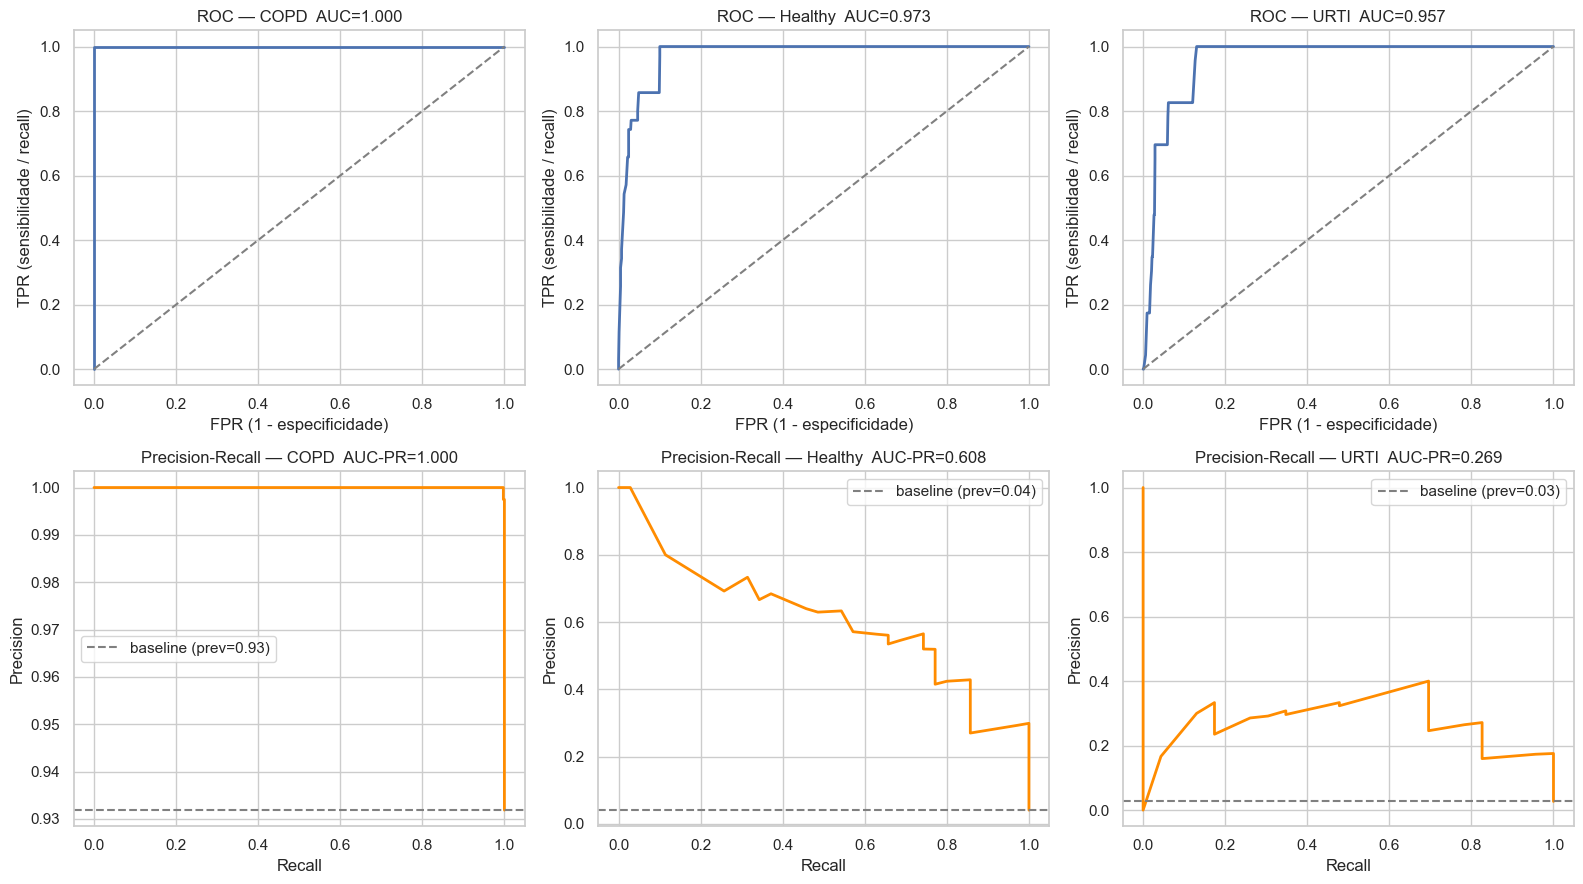

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for k, cls in enumerate(CLASSES):
    yk = (y == k).astype(int)
    pk = proba_cal[:, k]
    # ROC
    fpr, tpr, thr = roc_curve(yk, pk)
    roc_auc = auc(fpr, tpr)
    axes[0, k].plot(fpr, tpr, lw=2)
    axes[0, k].plot([0,1],[0,1],'--',color='gray')
    axes[0, k].set_title(f'ROC — {cls}  AUC={roc_auc:.3f}')
    axes[0, k].set_xlabel('FPR (1 - especificidade)')
    axes[0, k].set_ylabel('TPR (sensibilidade / recall)')
    # PR
    prec, rec, thr_pr = precision_recall_curve(yk, pk)
    pr_auc = auc(rec, prec)
    axes[1, k].plot(rec, prec, lw=2, color='darkorange')
    axes[1, k].set_title(f'Precision-Recall — {cls}  AUC-PR={pr_auc:.3f}')
    axes[1, k].set_xlabel('Recall'); axes[1, k].set_ylabel('Precision')
    # baseline = prevalência
    axes[1, k].axhline(yk.mean(), color='gray', linestyle='--',
                       label=f'baseline (prev={yk.mean():.2f})')
    axes[1, k].legend()
plt.tight_layout(); plt.show()

## 3. Curvas ROC úteis para escolher operação por classe

**Atenção:** thresholds independentes por classe em multiclasse é problemático. A abordagem correta é **cost-sensitive decision rule** (seção 5) — minimiza custo esperado global. Mas antes, é informativo ver, classe a classe, o trade-off recall × precision.

In [4]:
rows = []
for k, cls in enumerate(CLASSES):
    yk = (y == k).astype(int)
    pk = proba_cal[:, k]
    # default 0.5
    pred = (pk >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yk, pred, labels=[0,1]).ravel()
    rec_d = tp/(tp+fn) if tp+fn else 0
    prec_d = tp/(tp+fp) if tp+fp else 0
    rows.append(dict(classe=cls, thr_default=0.5,
                      recall_default=rec_d, precision_default=prec_d,
                      FN_default=fn, FP_default=fp,
                      total_class=yk.sum()))
thr_df = pd.DataFrame(rows)
print('Operação atual (argmax / threshold 0.5 por classe):')
thr_df.round(3)

Operação atual (argmax / threshold 0.5 por classe):


,classe,thr_default,recall_default,precision_default,FN_default,FP_default,total_class
0,COPD,0.5,0.997,0.999,2,1,793
1,Healthy,0.5,0.629,0.564,13,17,35
2,URTI,0.5,0.261,0.286,17,15,23


## 4. Matriz de custos — valores reais do SNS português

Custos fundamentados em dados do Serviço Nacional de Saúde (Portugal):

| Patologia | Volume anual | Custo unitário | Impacto |
|---|---|---|---|
| **DPOC** | +10.000 internamentos | **€2.500–3.400** | Internamentos prolongados, oxigenoterapia domiciliária, medicação crónica |
| **URTI** | +800.000 ocorrências | **€35–110** | Sobrecarga Linha SNS 24, urgências, absentismo laboral |

Derivação da matriz de custos C[real, predito] (€):

- **FN_DPOC (COPD → Healthy)**: €2.950 — média do internamento evitável; doente vai embora sem diagnóstico
- **DPOC → URTI**: €1.475 — tratamento parcial, metade do risco do internamento
- **FN_URTI (URTI → Healthy)**: €70 — média da consulta/urgência repetida
- **FP (Healthy → doente)**: €70 — consulta extra + auscultação presencial

Como temos **multiclasse**, definimos uma matriz de custos C[real, predito].

In [5]:
# Custos em € — dados reais do SNS português (linhas=real, colunas=predito)
# DPOC: €2.500-3.400/internamento (média 2.950) | URTI: €35-110/ocorrência (média 70)
COSTS = pd.DataFrame(
    [[0,     2950,  1475],   # real=COPD: FN grave (internamento evitável)
     [70,    0,     70],     # real=Healthy: FP = consulta extra
     [70,    70,    0]],     # real=URTI: FN = consulta/urgência repetida
    index=CLASSES, columns=CLASSES)
print('Matriz de custos clínicos — SNS Portugal (€):')
print(COSTS)
print()
print('Volumes anuais de referência: DPOC ~10.000 internamentos | URTI ~800.000 ocorrências')

Matriz de custos clínicos — SNS Portugal (€):
         COPD  Healthy  URTI
COPD        0     2950  1475
Healthy    70        0    70
URTI       70       70     0

Volumes anuais de referência: DPOC ~10.000 internamentos | URTI ~800.000 ocorrências


In [6]:
# Função de custo total
def total_cost(y_true, y_pred, costs):
    total = 0
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            n = ((y_true == i) & (y_pred == j)).sum()
            total += n * costs.iloc[i, j]
    return total

# A — argmax (otimiza accuracy, ignora custos)
y_pred_argmax = np.argmax(proba_cal, axis=1)
cost_argmax = total_cost(y, y_pred_argmax, COSTS)

# B — cost-sensitive decision rule: predito = argmin_j Σ_i C[i,j] * P(real=i|x)
# Para cada amostra x, escolhemos a classe que MINIMIZA o custo esperado.
C_mat = COSTS.values   # (n_classes_real, n_classes_pred)
expected_cost = proba_cal @ C_mat    # shape (n_samples, n_classes_pred)
y_pred_cs = np.argmin(expected_cost, axis=1)
cost_cs = total_cost(y, y_pred_cs, COSTS)

print(f'A — argmax (otimiza acc):       € {cost_argmax:,.0f}')
print(f'B — cost-sensitive (otimiza €): € {cost_cs:,.0f}')
delta = cost_argmax - cost_cs
print(f'\nDelta: € {delta:+,.0f}  ({100*delta/cost_argmax:+.1f}%)')
if delta > 0:
    print(f'→ Cost-sensitive ECONOMIZA € {delta:,.0f} ({len(y)} pacientes do CV)')
else:
    print(f'→ Cost-sensitive piorou em € {-delta:,.0f}')

A — argmax (otimiza acc):       € 5,120
B — cost-sensitive (otimiza €): € 2,450

Delta: € +2,670  (+52.1%)
→ Cost-sensitive ECONOMIZA € 2,670 (851 pacientes do CV)


## 5. Matriz de confusão lado a lado

Vemos visualmente onde os erros migram quando ajustamos o threshold.

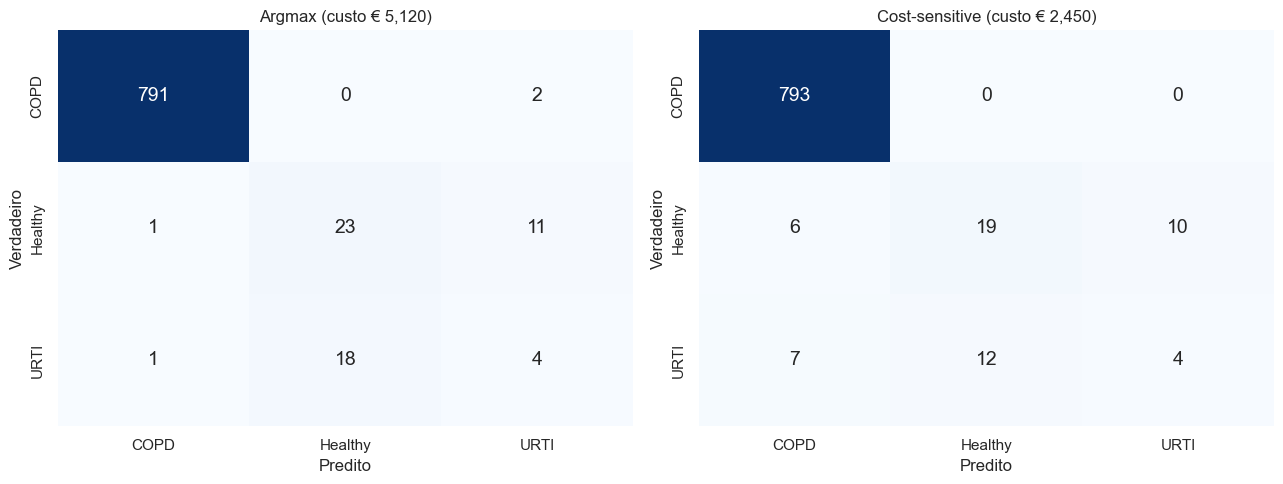


FN/FP por classe (cost-sensitive vs argmax):


,classe,FN_argmax,FP_argmax,FN_cs,FP_cs,delta_FN,delta_FP
0,COPD,2,2,0,13,-2,11
1,Healthy,12,18,16,12,4,-6
2,URTI,19,13,19,10,0,-3


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, y_pred, title in [(axes[0], y_pred_argmax, f'Argmax (custo € {cost_argmax:,.0f})'),
                            (axes[1], y_pred_cs,    f'Cost-sensitive (custo € {cost_cs:,.0f})')]:
    cm = confusion_matrix(y, y_pred, labels=range(len(CLASSES)))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES, cbar=False,
                annot_kws={'size': 14}, ax=ax)
    ax.set_xlabel('Predito'); ax.set_ylabel('Verdadeiro')
    ax.set_title(title)
plt.tight_layout(); plt.show()

# Comparativo FN/FP por classe doente
comparativo = []
for cls in CLASSES:
    k = CLASSES.index(cls)
    fn_a = ((y == k) & (y_pred_argmax != k)).sum()
    fp_a = ((y != k) & (y_pred_argmax == k)).sum()
    fn_b = ((y == k) & (y_pred_cs != k)).sum()
    fp_b = ((y != k) & (y_pred_cs == k)).sum()
    comparativo.append(dict(classe=cls,
                              FN_argmax=fn_a, FP_argmax=fp_a,
                              FN_cs=fn_b, FP_cs=fp_b,
                              delta_FN=fn_b - fn_a, delta_FP=fp_b - fp_a))
print('\nFN/FP por classe (cost-sensitive vs argmax):')
pd.DataFrame(comparativo)

## 6. Projeção de impacto financeiro anual (escala nacional SNS)

Considerando o volume nacional de **~810.000 ocorrências respiratórias/ano** em Portugal (10.000 internamentos DPOC + 800.000 ocorrências URTI). Usamos 50.000 como cenário de **adoção parcial** (~6% do volume nacional, ou um conjunto de ULS de médio porte).

In [8]:
VOLUME_ANUAL = 50_000  # cenário de adoção parcial (~6% do volume nacional respiratório)
n = len(y)
cost_per_pat_argmax = cost_argmax / n
cost_per_pat_cs     = cost_cs / n
annual_argmax = cost_per_pat_argmax * VOLUME_ANUAL
annual_cs     = cost_per_pat_cs     * VOLUME_ANUAL
print(f'Custo médio por paciente:')
print(f'  argmax          : € {cost_per_pat_argmax:,.2f}')
print(f'  cost-sensitive  : € {cost_per_pat_cs:,.2f}')
print()
print(f'Projeção anual ({VOLUME_ANUAL:,} pacientes):')
print(f'  argmax          : € {annual_argmax:,.0f}')
print(f'  cost-sensitive  : € {annual_cs:,.0f}')
print(f'  ECONOMIA        : € {(annual_argmax - annual_cs):,.0f} / ano')

Custo médio por paciente:
  argmax          : € 6.02
  cost-sensitive  : € 2.88

Projeção anual (50,000 pacientes):
  argmax          : € 300,823
  cost-sensitive  : € 143,948
  ECONOMIA        : € 156,874 / ano


Sensibilidade ao custo de FN_COPD (decisão re-otimizada):
   custo_FN_COPD_EUR  economia_anual_EUR  FN_COPD_cs
0                500             12926.0           0
1               1000             42303.0           0
2               1500             71680.0           0
3               2500            130435.0           0
4               4000            218566.0           0


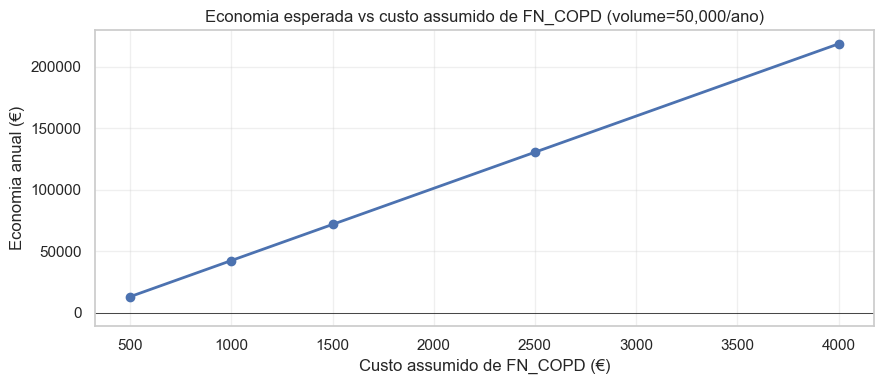

In [9]:
# Sensitivity: e se o custo de FN_COPD for diferente?
# IMPORTANTE: re-otimizar a decisão para cada custo (a regra cost-sensitive depende da matriz)
fn_costs = [500, 1000, 1500, 2500, 4000]
savings = []
for c in fn_costs:
    C2 = COSTS.copy()
    C2.loc['COPD', 'Healthy'] = c
    C2.loc['COPD', 'URTI']    = c // 2
    # recomputar decisão cost-sensitive com nova matriz
    exp_c = proba_cal @ C2.values
    y_pred_cs2 = np.argmin(exp_c, axis=1)
    s_arg = total_cost(y, y_pred_argmax, C2)
    s_cs  = total_cost(y, y_pred_cs2,    C2)
    annual_save = (s_arg - s_cs) / n * VOLUME_ANUAL
    fn_copd = ((y == CLASSES.index('COPD')) & (y_pred_cs2 != CLASSES.index('COPD'))).sum()
    savings.append((c, annual_save, fn_copd))
sens_df = pd.DataFrame(savings, columns=['custo_FN_COPD_EUR', 'economia_anual_EUR', 'FN_COPD_cs']).round(0)
print('Sensibilidade ao custo de FN_COPD (decisão re-otimizada):')
print(sens_df)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sens_df['custo_FN_COPD_EUR'], sens_df['economia_anual_EUR'], 'o-', lw=2)
ax.set_xlabel('Custo assumido de FN_COPD (€)')
ax.set_ylabel('Economia anual (€)')
ax.set_title(f'Economia esperada vs custo assumido de FN_COPD (volume={VOLUME_ANUAL:,}/ano)')
ax.grid(alpha=0.3)
ax.axhline(0, color='black', linewidth=0.5)
plt.tight_layout(); plt.show()

## 7. Resumo executivo

**Estratégia correta: Cost-Sensitive Decision Rule.**
Em vez de thresholds isolados por classe (quebra em multiclasse), usamos:
$$\hat y = \arg\min_j \sum_i C_{ij}\,P(y=i\mid x)$$
ou seja, predizemos a classe com **menor custo esperado** dada a matriz de custos clínicos.

**Por que isso funciona melhor:**
- Considera **as 3 probabilidades simultaneamente**.
- Decisão final coerente: se P(COPD) é 30% mas custo de errar é alto, ainda pode compensar predizer COPD.
- Não "força" recall alto a qualquer custo — o trade-off vem dos parâmetros da matriz.

**Para gestão / decisão clínica:**
1. O modelo pode ser **deployado como triagem**: pacientes preditos como COPD pelo cost-sensitive rule passam por avaliação prioritária.
2. Pacientes com `confidence == 'alta'` e `outlier == False` (do nb09) podem ser **fast-tracked**.
3. Pacientes com confiança baixa ou outlier: **encaminhados para auscultaão presencial** com médico.
4. **A matriz de custos é um parâmetro de governança** — não é só técnica, é decisão gerencial/clínica que define o ponto de operação. Pode ser ajustada conforme realidade local do hospital (custos de internação reais, capacidade ambulatorial, etc.).